In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt 
%matplotlib inline

In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
# build the vocab of chars and mapping to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [31]:
# build the dataset
block_size = 3     # context lenght: how many chars do we take to predict the next one?

def build_dataset(words):
    X, Y = [], []
    for w in words:
        
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]      # crop and append
            
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182580, 3]) torch.Size([182580])
torch.Size([22767, 3]) torch.Size([22767])
torch.Size([22799, 3]) torch.Size([22799])


In [32]:
# MLP revisited
n_emb = 10         # the dimentionality of the chars embeding vectors
n_hidden = 200     # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)              # for reproducibility
C = torch.randn((vocab_size, n_emb),                generator=g)
W1 = torch.randn((n_emb * block_size, n_hidden),    generator=g) * (5/3) / ((n_emb * block_size)**0.5)
b1 = torch.randn(n_hidden,                          generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0 

bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parametres = [C, W1, b1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parametres)) # number of params in total
for p in parametres:
    p.requires_grad = True

12297


tensor(-0.0143) tensor(1.0073)
tensor(0.0020) tensor(1.0131)


(array([4.57083972e-05, 2.28541986e-05, 4.57083972e-05, 1.82833589e-04,
        2.05687787e-04, 5.02792369e-04, 5.48500766e-04, 1.18841833e-03,
        2.44539925e-03, 3.19958780e-03, 5.25646568e-03, 9.14167944e-03,
        1.27754970e-02, 1.98831528e-02, 3.26129414e-02, 4.55712720e-02,
        6.85625958e-02, 9.97585769e-02, 1.39364903e-01, 1.85873197e-01,
        2.37523686e-01, 3.00007065e-01, 3.50674823e-01, 3.98142994e-01,
        4.23145487e-01, 4.14026662e-01, 3.91309588e-01, 3.41875957e-01,
        2.86865901e-01, 2.25296690e-01, 1.73234825e-01, 1.25538113e-01,
        9.15539196e-02, 6.29404629e-02, 4.28287682e-02, 2.94362078e-02,
        1.88547138e-02, 1.13813909e-02, 7.86184432e-03, 4.04519315e-03,
        2.71964963e-03, 1.78262749e-03, 1.00558474e-03, 8.91313745e-04,
        3.19958780e-04, 2.51396185e-04, 9.14167944e-05, 0.00000000e+00,
        2.28541986e-05, 2.28541986e-05]),
 array([-5.44090509, -5.22212691, -5.00334873, -4.78457055, -4.56579237,
        -4.34701419, 

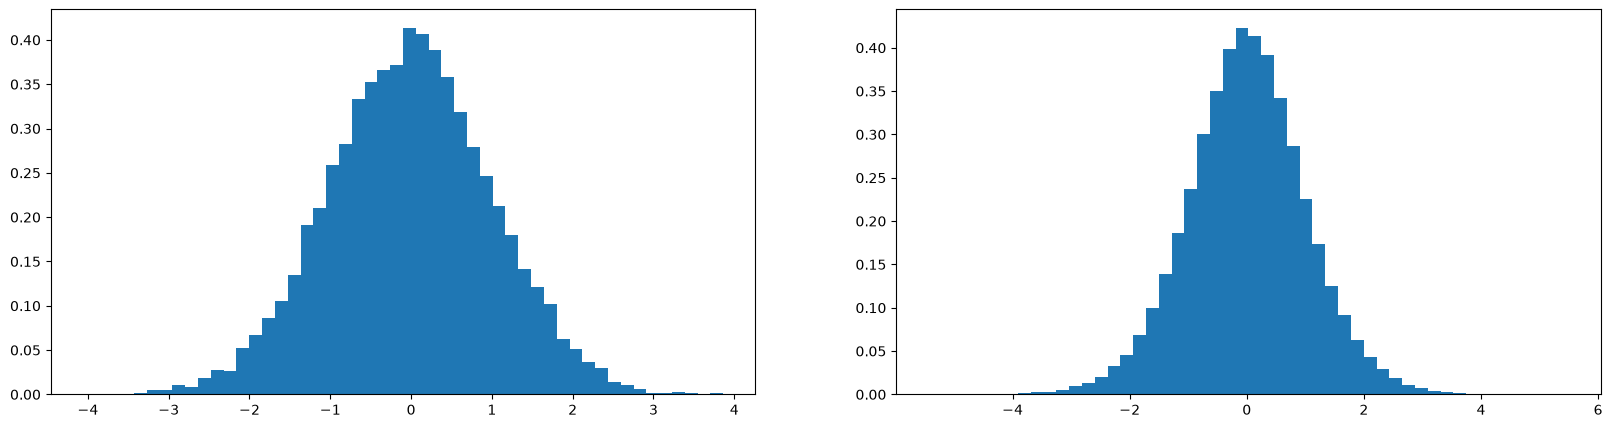

In [33]:
x = torch.randn(1000, 10)
w = torch.randn(10, 200) / 10**0.5
y = x @ w
print(x.mean(), x.std())
print(y.mean(), y.std())
plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density=True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True)

In [13]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ))
    Xb, Yb = Xtr[ix], Ytr[ix]
    
    # forward pass
    emb = C[Xb]                                                  # (32, 3, 2)
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 # +  b1
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias
    
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    
    h = torch.tanh(hpreact)                                     # (32, 100)
    logits = h @ W2 + b2                                        # (32, 27)
    loss = F.cross_entropy(logits, Ytr[ix])
    

    # backward pass
    for p in parametres:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parametres:
        p.data += -lr * p.grad
        
    # track stats
    if i % 10000 == 0 :
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

# print(loss.item())

TypeError: unsupported operand type(s) for *: 'float' and 'NoneType'

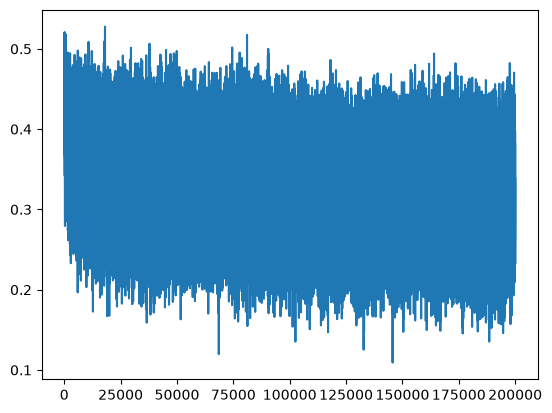

In [ ]:
plt.plot(lossi)

In [30]:
# calibrate the batch norm at the end of training

with torch.no_grad():
    # pass the training set through
    emb = C[Xtr]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    # measure the mean/std over the entire training set
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim=True)

In [29]:
@torch.no_grad() # this decoratordisablegradienttracing
def split_loss(split):
    x,y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test': (Xte, Yte)
    }[split]
    emb = C[x] # (N, block_size, n_embd)
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    # hpreact = bngain * (hpreact - hpreact.mean(0, keepdim=True)) / hpreact.std(0, keepdim=True) + bnbias
    hpreact = bngain * (hpreact - bnmean) / bnstd + bnbias
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())
    
split_loss('train')
split_loss('val')

train 3.2973692417144775
val 3.2962887287139893


In [10]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size
    while True:
        # forward pass the nn
        emb = C[torch.tensor([context])] # (1, block_size, n_embd)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        
        # sample for the distribution
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        
        # shift the context window and track the samples
        context = context[1:] + [ix]
        out.append(ix)
        
        # if we sample the special '.' token, break
        if ix == 0:
            break
    print(''.join(itos[i] for i in out))

cbrpzhxqtbfhqvkfkwmrpxqthtykhkcaqskejrzhnbnfqpwsyhc.
vgqhiunrzmuqptcmziivduxlhggphhbmgpoindqbqjtzsrlivwa.
vvdbquwqzthogdjaryxixfkqeupiusdbwed.
ecoiatgtlffhysflquhpqgmovdjhksyjrpmqqosozswjcojqmwyojsfrenqkpfsadlnuo.
zoebsrkoiyzhrynhg.
opklhynrxyh.
xqioloqbplbvbwdn.
ipyqmuitjpbvfpzpddgpycsislqwkkmconzauqnljydpk.
kvweskatikzamdtevl.
ky.
qdyctoorowooktbymouokfbfcw.
zoindzcs.
nu.
eoaignqqerosci.
icfzykbadyieluglconwzyzdjokhnlhjjqsxmuadltjhvtoyaplwuw.
xisxwrmfv.
qphtzbiuzzsrvgmknbfyntiysfgdgkgmmj.
pqgcrvdhpvdafpsdvkhzkxkidtvoscvupgawjmjqjwgvhflwkewtxarclxdytlvhgqllyuil.
hhza.
gfcmkjpoubjbiygh.


# deeper network

In [48]:
class Linear:
    def __init__(self, fan_in, fan_out, bias = True):
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None
        
    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out
    
    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])
    
class BatchNorm1d:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        # parameters (trained with backprop)
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        # buffers (trained with running 'momentum update')
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)
        
    def __call__(self, x):
        # calculate the forward pass
        if self.training:
            xmean = x.mean(0, keepdim=True)                 # batch mean
            xvar = x.var(0, keepdim=True, unbiased=True)    # batch varience
        else:
            xmean = self.running_mean
            xvar = self.runnig_var
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)    # normalise tou unit variance
        self.out = self.gamma * xhat + self.beta
        # update the buffer
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var+ self.momentum * xvar
        return self.out
    
    def parameters(self):
        return [self.gamma, self.beta]
    
class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []
    
n_emb = 10                                      # dim of the chars embedding vectors
n_hidden = 100                                  # nb of neuron in the hidden layen
g = torch.Generator().manual_seed(2147483647)   # for reproducibility

C = torch.randn((vocab_size, n_emb), generator=g)
layers = [
    Linear(n_emb * block_size, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(          n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(          n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(          n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(          n_hidden, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(          n_hidden, vocab_size), BatchNorm1d(vocab_size),
]

with torch.no_grad():
    # last layer: make less confident
    # layers[-1].weight *= 0.1
    layers[-1].gamma *= 0.1
    
    # all others layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3
            
parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters)) # number of params in total
for p in parameters:
    p.requires_grad = True

47551


In [49]:
# same opti than last time
max_steps = 200000
batch_size = 32
lossi = []
ud = []

for i in range(max_steps):
    
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]
    
    # forward pass
    emb = C[Xb]                                                  # (32, 3, 2)
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb)

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # AFTER_DEBUG : would take out retain_graph 
    for p in parametres:
        p.grad = None
        
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad
        
    # track stats
    if i % 10000 == 0 :
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])
    
    if i >= 1000:
        break

# print(loss.item())

      0/ 200000: 3.3313


layer 2 (      Tanh): mean +0.01, std 0.97, saturated: 87.06%
layer 5 (      Tanh): mean +0.10, std 0.94, saturated: 78.47%
layer 8 (      Tanh): mean +0.10, std 0.94, saturated: 78.34%
layer 11 (      Tanh): mean -0.01, std 0.96, saturated: 84.84%
layer 14 (      Tanh): mean +0.09, std 0.99, saturated: 95.38%


Text(0.5, 1.0, 'activation distribution')

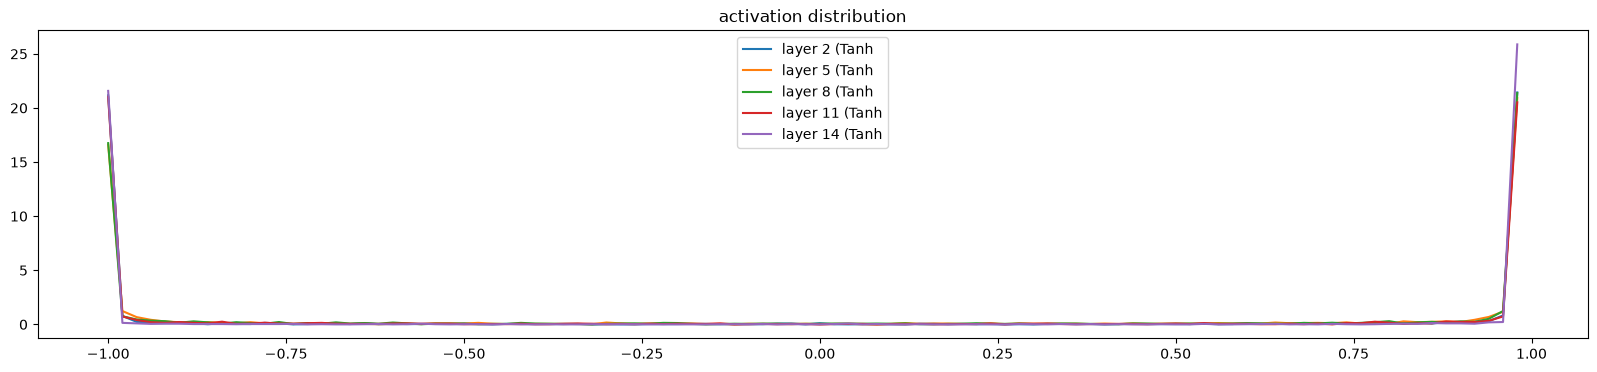

In [50]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

layer 2 (      Tanh): mean +0.00, std 0.01, saturated: 0.00%
layer 5 (      Tanh): mean +0.00, std 0.01, saturated: 0.00%
layer 8 (      Tanh): mean -0.00, std 0.00, saturated: 0.00%
layer 11 (      Tanh): mean +0.00, std 0.00, saturated: 0.00%
layer 14 (      Tanh): mean +0.00, std 0.00, saturated: 0.00%


Text(0.5, 1.0, 'activation distribution')

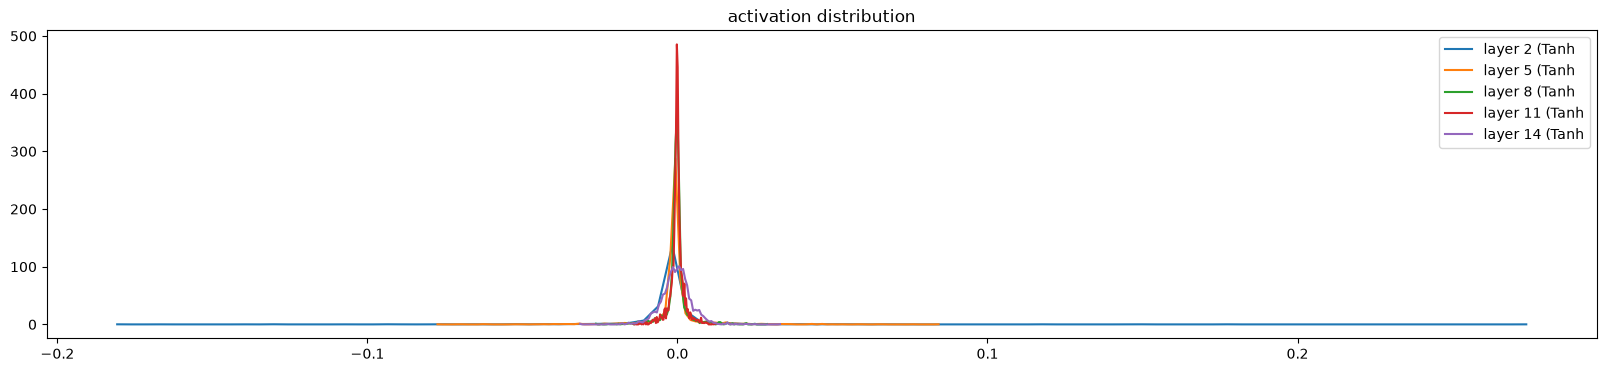

In [51]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

weight   (27, 10) | mean -0.000000 | std 1.286176e-01 | grad:data ratio 1.326245e-02
weight  (30, 100) | mean -0.001778 | std 6.006588e-02 | grad:data ratio 1.593838e-02
weight (100, 100) | mean -0.000162 | std 2.891046e-02 | grad:data ratio 1.273086e-02
weight (100, 100) | mean -0.000121 | std 2.439483e-02 | grad:data ratio 1.239666e-02
weight (100, 100) | mean +0.000075 | std 2.283843e-02 | grad:data ratio 1.189082e-02
weight (100, 100) | mean -0.000427 | std 2.564373e-02 | grad:data ratio 1.280717e-02
weight  (100, 27) | mean +0.000410 | std 6.481891e-02 | grad:data ratio 1.214897e-02


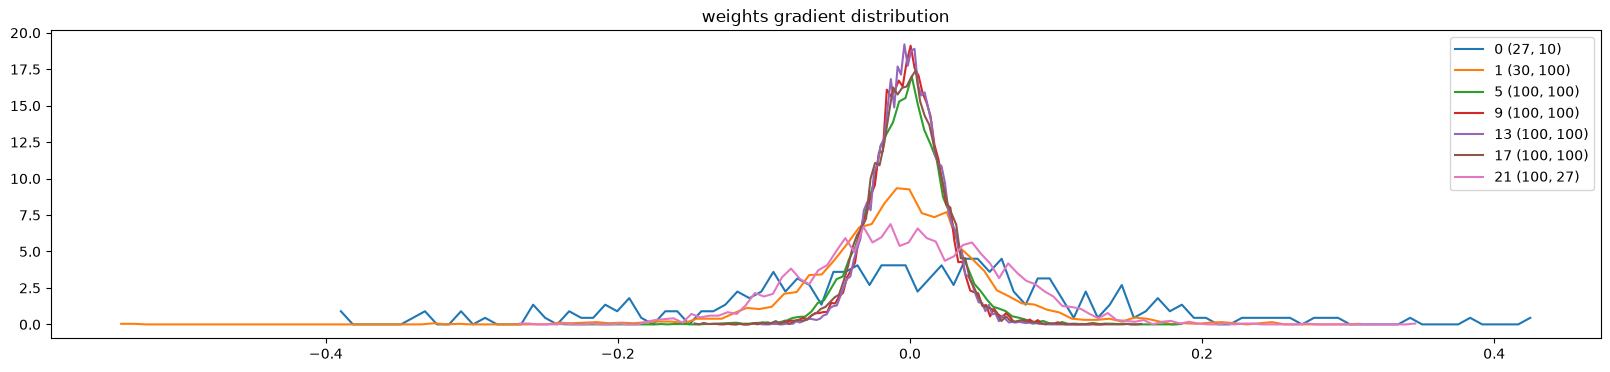

In [52]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

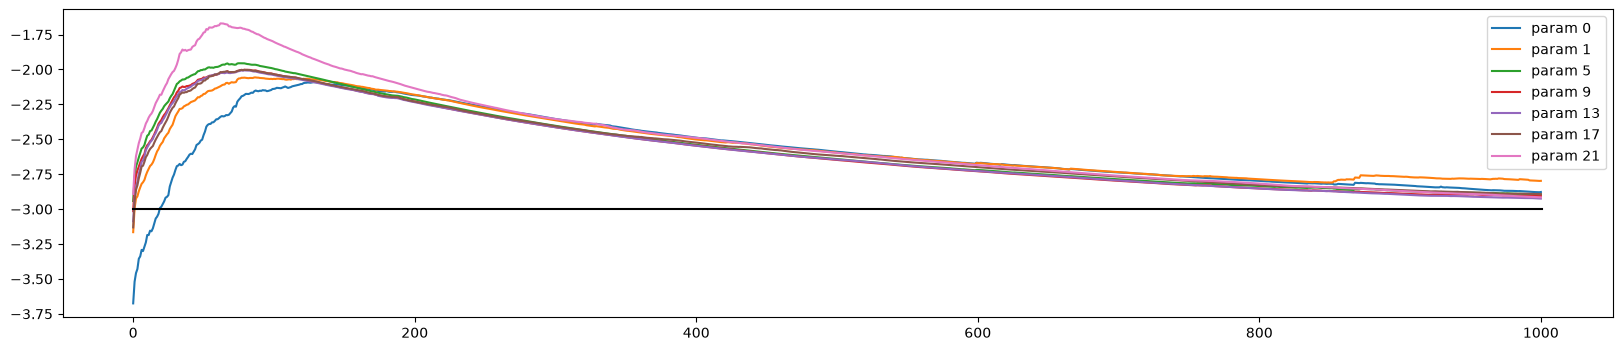

In [53]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);